## LangGraph + RAG

In [1]:
# Install this notebook's direct dependencies.
%pip install -qU langgraph langchain-openai langchain-community langchain-text-splitters faiss-cpu python-dotenv
# Google Colab: add OPENAI_API_KEY in the Secrets panel (🔑) and grant this notebook access.
# Uncomment these lines to load it from Colab Secrets into this runtime:
# from google.colab import userdata
# import os
# os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")
# Locally, put OPENAI_API_KEY=... in a .env file; do not commit the key.

Note: you may need to restart the kernel to use updated packages.


In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, END
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.prompts import ChatPromptTemplate
from dotenv import load_dotenv

load_dotenv()

llm = ChatOpenAI(model="gpt-4o-mini")

/tmp/ipykernel_368821/35218668.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


### Preparing the document database

In [3]:
docs = [
    "LangChain is a framework for working with large language models.",
    "Langgraph is a framework that allows you to build workflows in the form of state graphs.",
    "Retrieval-Augmented Generation (RAG) combines Context retrieval and response generation.",
    "FAISS is a library for finding the closest vectors in embeddings."
]

# Division into chunks
splitter = RecursiveCharacterTextSplitter(chunk_size=100, chunk_overlap=10)
splits = splitter.create_documents(docs)

# Index in vector database
embeddings = OpenAIEmbeddings()
vectorstore = FAISS.from_documents(splits, embedding=embeddings)
retriever = vectorstore.as_retriever(search_kwargs={"k": 2})

### State

In [4]:
class State(TypedDict):
    question: str
    context: str
    answer: str
    pass_eval: bool

### Retrieval node

In [5]:
def retrieval(state: State) -> State:
    docs = retriever.invoke(state["question"])
    context = "\\n".join([d.page_content for d in docs])
    return {"context": context}

### Generation node

In [6]:
prompt = ChatPromptTemplate.from_messages([
    ("system", "You are an assistant who locates information in documents. Respond only based on CONTEXT:\\n{context}"),
    ("user", "{question}")
])

def generation(state: State) -> State:
    response = (prompt | llm).invoke({
        "context": state["context"],
        "question": state["question"]
    })
    return {"answer": response.content}

### Evaluation node

In [7]:
eval_prompt = ChatPromptTemplate.from_messages([
    ("system", "Evaluate answer."),
    ("user", "Question: {question}\\nAnswer: {answer}\\nDoes the answer contain a needed information? Answer only 'yes' or 'no'.")
])

def eval_node(state: State) -> State:
    response = (eval_prompt | llm).invoke({
        "question": state["question"],
        "answer": state["answer"]
    })
    result = response.content.strip().lower().startswith("yes")
    return {"pass_eval": result}

### Final node

In [8]:
def finish(state: State) -> State:
    if state["pass_eval"]:
        print(f"✅ Answer approved: {state['answer']}")
    else:
        print("❌ The answer does not contain a solution.")
    return state

### Graph structure

In [9]:
graph = StateGraph(State)

graph.add_node("retrieval", retrieval)
graph.add_node("generation", generation)
graph.add_node("eval", eval_node)
graph.add_node("finish", finish)

graph.set_entry_point("retrieval")
graph.add_edge("retrieval", "generation")
graph.add_edge("generation", "eval")

def check_eval(state: State):
    return "finish" if state["pass_eval"] else "generation"

graph.add_conditional_edges("eval", check_eval, ["finish", "generation"])
graph.add_edge("finish", END)

app = graph.compile(debug=True)

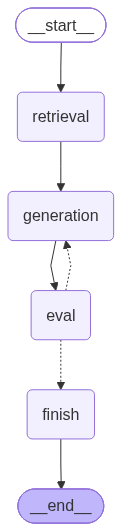

In [10]:
# Graph visualization
from IPython.display import Image, display

png_bytes = app.get_graph().draw_mermaid_png()
display(Image(png_bytes))

### Run graph

In [11]:
app.invoke({"question": "What is a LangGraph?"})

[values] {'question': 'What is a LangGraph?'}
[updates] {'retrieval': {'context': 'Langgraph is a framework that allows you to build workflows in the form of state graphs.\\nLangChain is a framework for working with large language models.'}}
[values] {'question': 'What is a LangGraph?', 'context': 'Langgraph is a framework that allows you to build workflows in the form of state graphs.\\nLangChain is a framework for working with large language models.'}
[updates] {'generation': {'answer': 'Langgraph is a framework that allows you to build workflows in the form of state graphs.'}}
[values] {'question': 'What is a LangGraph?', 'context': 'Langgraph is a framework that allows you to build workflows in the form of state graphs.\\nLangChain is a framework for working with large language models.', 'answer': 'Langgraph is a framework that allows you to build workflows in the form of state graphs.'}
[updates] {'eval': {'pass_eval': True}}
[values] {'question': 'What is a LangGraph?', 'context'

{'question': 'What is a LangGraph?',
 'context': 'Langgraph is a framework that allows you to build workflows in the form of state graphs.\\nLangChain is a framework for working with large language models.',
 'answer': 'Langgraph is a framework that allows you to build workflows in the form of state graphs.',
 'pass_eval': True}